In [1]:
from dask.distributed import Client

client = Client("tcp://127.0.0.1:45951")
client

<Client: 'tcp://127.0.0.1:45951' processes=10 threads=40, memory=629.62 GiB>

In [2]:
import numpy as np
import xarray as xr
import os.path as op
import gsw

from xgcm.grid import Grid
from scipy.optimize import curve_fit

import cartopy.crs as ccrs
import cartopy.feature as cfeature
import cmocean

import matplotlib.pyplot as plt
%matplotlib inline

In [3]:
ddir = "/storage/tartar/takaya/bruno/basilisk/"

In [4]:
ds = xr.open_dataset(op.join(ddir,"MSQG/vars_0009.nc")
                    ).isel(time=slice(50,None)
                          ).chunk({"time":4,"level":1,"y":128,"x":256})
dsin = xr.open_dataset(op.join(ddir,"MSQG/input_vars_5l_N1024.nc")
                      ).isel(t=0).chunk({"z":1,"y":128,"x":256})
ds, dsin

(<xarray.Dataset> Size: 9GB
 Dimensions:  (time: 297, level: 5, y: 513, x: 1025)
 Coordinates:
   * time     (time) float32 1kB 1.037e+08 1.063e+08 ... 8.683e+08 8.709e+08
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06
 Data variables:
     psi      (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     psi_f    (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     q        (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
 Attributes:
     history:  Mon Sep 14 12:31:23 2026: ncrcat -O tmp_vars/vars_0015.nc tmp_v...
     NCO:      netCDF Operators version 5.1.9 (Homepage = http://nco.sf.net, C...,
 <xarray.Dataset> Size: 27MB
 Dimensions:  (z: 5, y: 513, x: 1025)
 Coordinates:
   * z        (z) float32 20B 0.0 1.0 2.0 3.

In [5]:
sshb = xr.DataArray(dsin.psi_pg.isel(z=0).data,
                   dims=["y","x"],
                   coords={"y":ds.y.data,"x":ds.x.data}
                  )

dz = xr.DataArray(np.array([250,250,250,250,3000]), 
                  dims="level",
                  coords={"level":ds.level.data}
                 )
Zp1 = np.concatenate((np.array([0.,]), -np.cumsum(dz.data)))
Z = .5*(Zp1[1:]+Zp1[:-1])
print(Z,Zp1)

ds["Zp1"] = xr.DataArray(Zp1, dims="lp1",
                          coords={"lp1":np.array([-.5,0.5,1.5,2.5,3.5,4.5])}
                         )
ds["Z"] = xr.DataArray(Z, dims="level",
                        coords={"level":ds.level.data}
                       )
ds["N2"] = xr.DataArray(dsin.N2.data, dims=["level","y","x"],
                        coords=ds.psi.isel(time=0).coords)

# llo, lla = np.meshgrid(dsp.x, dsp.y)
# xxG = xr.DataArray(gsw.distance(llo, lla), dims=["y","xG"],
#                   coords={"y":dsp.y.data,
#                           "xG":.5*(dsp.x.data[1:]+dsp.x.data[:-1])}
#                  )
# yyG = xr.DataArray(gsw.distance(llo, lla, axis=0), dims=["yG","x"],
#                   coords={"yG":.5*(dsp.y.data[1:]+dsp.y.data[:-1]),
#                           "x":dsp.x.data}
#                  )
ds.coords["yG"] = ("yG",.5*(ds.y.data[1:]+ds.y.data[:-1]))
ds.coords["xG"] = ("xG",.5*(ds.x.data[1:]+ds.x.data[:-1]))

grid = Grid(ds, padding={'X': 'extend', 'Y': 'extend', "Z": "extend"}, 
            autoparse_metadata=False,
            coords={"X": {"center": "x", "inner": "xG"},
                    "Y": {"center": "y", "inner": "yG"},
                    "Z": {"center": "level", "outer": "lp1"}
                   })

ds, grid

[ -125.  -375.  -625.  -875. -2500.] [    0.  -250.  -500.  -750. -1000. -4000.]


(<xarray.Dataset> Size: 9GB
 Dimensions:  (time: 297, level: 5, y: 513, x: 1025, lp1: 6, yG: 512, xG: 1024)
 Coordinates:
   * time     (time) float32 1kB 1.037e+08 1.063e+08 ... 8.683e+08 8.709e+08
   * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
   * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
   * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06
   * lp1      (lp1) float64 48B -0.5 0.5 1.5 2.5 3.5 4.5
   * yG       (yG) float32 2kB 3.906e+03 1.172e+04 ... 3.988e+06 3.996e+06
   * xG       (xG) float32 4kB 3.906e+03 1.172e+04 ... 7.988e+06 7.996e+06
 Data variables:
     psi      (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     psi_f    (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     q        (time, level, y, x) float32 3GB dask.array<chunksize=(4, 1, 128, 256), meta=np.ndarray>
     Zp1      (lp1) float64 48B 0.0 -250.0 -500.0 -750.0 -1e+03 -4e+0

In [6]:
Delta = 3.90625e+03
u = -(grid.diff(ds.psi.fillna(0.).chunk({"y":-1}),
                "Y",padding="extend") 
       / Delta)
v = (grid.diff(ds.psi.fillna(0.).chunk({"x":-1}),
               "X",padding="extend") 
      / Delta)

EKE = .5*(grid.interp(u**2,"Y",padding="extend") 
          + grid.interp(v**2,"X",padding="extend")
         ).mean("time").compute()
EKE

<xarray.DataArray 'psi' (level: 5, y: 513, x: 1025)> Size: 11MB
array([[[0.00000000e+00, 6.28691381e-13, 5.11274703e-12, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [6.28691381e-13, 3.49957368e-12, 1.77652806e-11, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [7.20610334e-12, 2.12336745e-11, 7.00482727e-11, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        ...,
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         5.58890235e-07, 1.56757338e-07, 4.97021198e-08],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         1.68753658e-07, 3.04457686e-08, 5.90138161e-09],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         5.65041240e-08, 5.90138161e-09, 0.00000000e+00]],

       [[0.00000000e+00, 2.69252936e-11, 2.26838423e-10, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [2.69252936e-11, 1.43177872e-10, 7.19425630e-10, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [2.82445983e-10, 8.01362754e-10, 2.49688958e-09, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
...
         3.85871999e-07, 1.02051402e-07, 3.39317516e-08],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         1.22822556e-07, 2.29406201e-08, 5.40751310e-09],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         4.68232386e-08, 5.40751310e-09, 0.00000000e+00]],

       [[0.00000000e+00, 9.64919551e-13, 8.52192275e-12, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [9.64919551e-13, 4.92431096e-12, 2.44008824e-11, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        [9.14150353e-12, 2.60356563e-11, 7.79546774e-11, ...,
         0.00000000e+00, 0.00000000e+00, 0.00000000e+00],
        ...,
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         1.29922671e-06, 3.75242877e-07, 1.30947143e-07],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         4.51149020e-07, 8.68112764e-08, 2.00002113e-08],
        [0.00000000e+00, 0.00000000e+00, 0.00000000e+00, ...,
         1.77547165e-07, 2.00002113e-08, 0.00000000e+00]]],
      shape=(5, 513, 1025), dtype=float32)
Coordinates:
  * level    (level) float32 20B 0.0 1.0 2.0 3.0 4.0
  * y        (y) float32 2kB 0.0 7.812e+03 1.562e+04 ... 3.992e+06 4e+06
  * x        (x) float32 4kB 0.0 7.812e+03 1.562e+04 ... 7.992e+06 8e+06

In [7]:
mask = dsin.mask
try:
  mask0 = dsin.mask0
except:
  mask0 = dsin.coastlines

mask0_nan = np.where(mask0 == 0, np.nan, 1)
mask0_c_nan = mask0_nan[:-1,:-1]

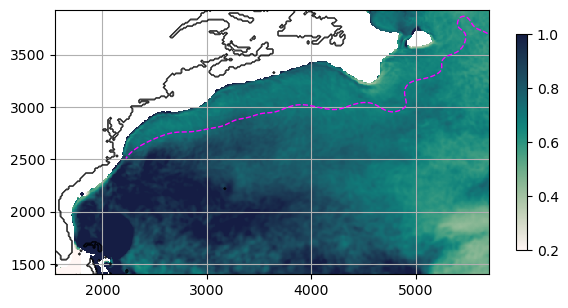

In [16]:
xmax = 5700
xmin = 1550
ymin = 1400
ymax = 3930

fig = plt.figure(figsize=(7,4))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlim([xmin, xmax], )
ax.set_ylim([ymin, ymax], )

im = ax.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               EKE.isel(level=1)/EKE.isel(level=0), 
               cmap=cmocean.cm.tempo,
               # cmap="RdBu_r",
               vmin=0.2, vmax=1.,
               )

ax.contour(ds.x*1e-3, ds.y*1e-3, 
           sshb.where(sshb.y>2500e3), 
           levels=np.array([26630,]), 
           colors="magenta", linestyles="dashed", linewidths=1)

ax.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
           colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax, shrink=.7)

ax.set_yticks([1500,2000,2500,3000,3500])
ax.set_xticks([2000,3000,4000,5000])

ax.grid(True)
ax.set_rasterized(True)
ax.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/EKE_msQGratio2-1.pdf"))

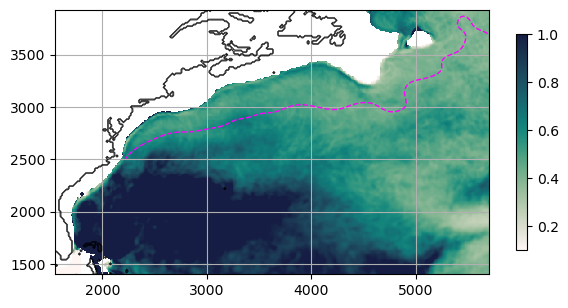

In [13]:
xmax = 5700
xmin = 1550
ymin = 1400
ymax = 3930

fig = plt.figure(figsize=(7,4))
ax = fig.add_subplot(1, 1, 1)
ax.set_xlim([xmin, xmax], )
ax.set_ylim([ymin, ymax], )

im = ax.pcolormesh(ds.x*1e-3, ds.y*1e-3, 
               EKE.isel(level=2)/EKE.isel(level=0), 
               cmap=cmocean.cm.tempo,
               # cmap="RdBu_r",
               vmin=0.1, vmax=1.,
               )

ax.contour(ds.x*1e-3, ds.y*1e-3, 
            sshb.where(sshb.y>2500e3), 
            levels=np.array([26630,]), 
            colors="magenta", linestyles="dashed", linewidths=1)

ax.contour(ds.x[::2]*1e-3, ds.y[::2]*1e-3, mask0[::2,::2], 
            colors="k", linewidths=.2, zorder=10)

cb = fig.colorbar(im, ax=ax, shrink=.7)

ax.set_yticks([1500,2000,2500,3000,3500])
ax.set_xticks([2000,3000,4000,5000])

ax.grid(True)
ax.set_rasterized(True)
ax.set_aspect("equal")

plt.savefig(op.join(ddir,"Figs/EKE_msQGratio3-1.pdf"))

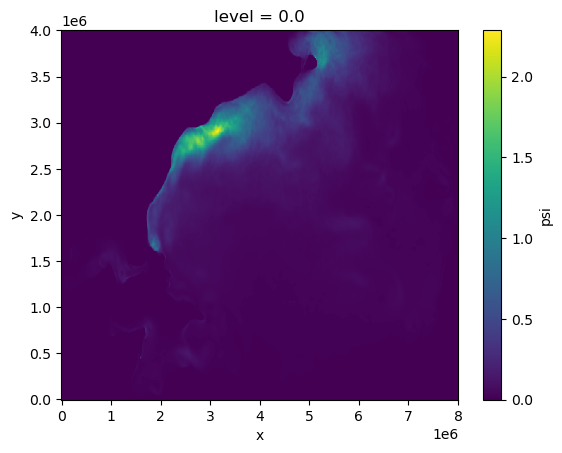

In [11]:
EKE.isel(level=0).plot(rasterized=True)

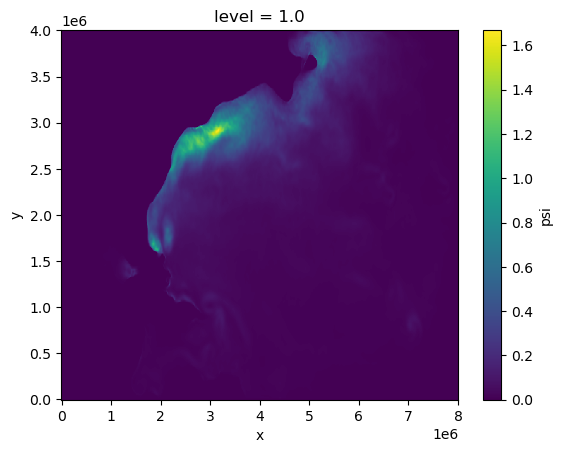

In [12]:
EKE.isel(level=1).plot(rasterized=True)